# Latihan Mandiri Pertemuan 4
## Pengantar Pemrosesan Paralel

Nama  : Najwa Azzahra   
NIM   : 2411513004          
Mata Kuliah : Pengantar Pemrosesan Paralel


## Soal 1 
Klasifikasi Flynn

In [ ]:
jawaban_flynn = """
a) Operasi arr + arr pada NumPy array
   Kategori : SIMD (Single Instruction, Multiple Data)
   Alasan   : Satu instruksi (operasi penjumlahan) dijalankan secara serentak
              pada banyak elemen data (seluruh elemen array) sekaligus.
              NumPy memanfaatkan vektorisasi/instruksi SIMD prosesor sehingga
              satu perintah "tambah" diterapkan ke banyak data dalam satu waktu.

b) Program Python biasa (tanpa threading/multiprocessing) yang membaca file
   lalu memproses baris demi baris
   Kategori : SISD (Single Instruction, Single Data)
   Alasan   : Program berjalan sekuensial pada satu thread/core, satu instruksi
              dieksekusi pada satu data (satu baris) pada satu waktu, baris
              berikutnya baru diproses setelah baris sebelumnya selesai.

c) Cluster komputer yang masing-masing node menjalankan simulasi cuaca
   berbeda untuk wilayah berbeda secara independen
   Kategori : MIMD (Multiple Instruction, Multiple Data)
   Alasan   : Tiap node adalah komputer independen yang menjalankan program
              (instruksi) yang bisa berbeda-beda terhadap data (wilayah) yang
              berbeda pula, saling independen satu sama lain -- ciri khas
              arsitektur terdistribusi/cluster.
"""
print(jawaban_flynn)


a) Operasi arr + arr pada NumPy array
   Kategori : SIMD (Single Instruction, Multiple Data)
   Alasan   : Satu instruksi (operasi penjumlahan) dijalankan secara serentak
              pada banyak elemen data (seluruh elemen array) sekaligus.
              NumPy memanfaatkan vektorisasi/instruksi SIMD prosesor sehingga
              satu perintah "tambah" diterapkan ke banyak data dalam satu waktu.

b) Program Python biasa (tanpa threading/multiprocessing) yang membaca file
   lalu memproses baris demi baris
   Kategori : SISD (Single Instruction, Single Data)
   Alasan   : Program berjalan sekuensial pada satu thread/core, satu instruksi
              dieksekusi pada satu data (satu baris) pada satu waktu, baris
              berikutnya baru diproses setelah baris sebelumnya selesai.

c) Cluster komputer yang masing-masing node menjalankan simulasi cuaca
   berbeda untuk wilayah berbeda secara independen
   Kategori : MIMD (Multiple Instruction, Multiple Data)
   Alasan   : Tiap node

## Soal 2
 Analisis Amdahl

Sebuah aplikasi pengolahan citra memiliki proporsi paralel P = 0.85.    
 Menghitung speedup teoritis untuk N = 2, 4, 8, 16, 32, 64 (menggunakan fungsi `amdahl_speedup`)   
 Membuat plot speedup vs N   
 Menentukan pada N berapa penambahan prosesor mulai memberikan manfaat yang sangat kecil (*diminishing returns*)   

     N | Speedup S(N)
-----------------------
     2 |       1.7391
     4 |       2.7586
     8 |       3.9024
    16 |       4.9231
    32 |       5.6637
    64 |       6.1244

Speedup maksimum teoritis (N -> tak hingga): 6.6667x


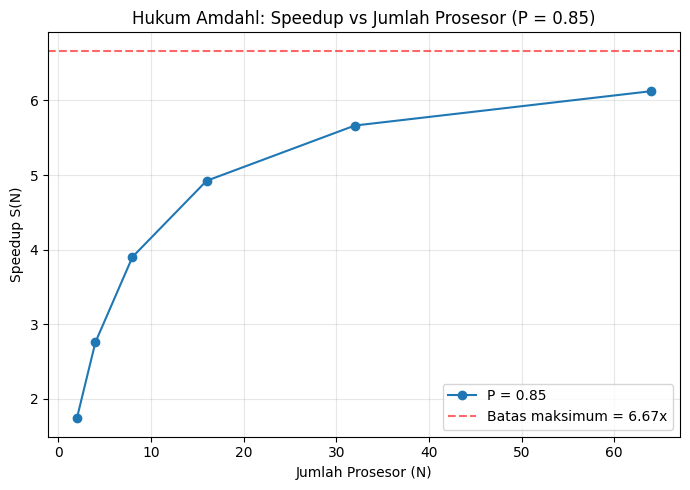


Kenaikan speedup tiap penggandaan N:
  N=  2 -> N=  4 : kenaikan speedup = 1.0195
  N=  4 -> N=  8 : kenaikan speedup = 1.1438
  N=  8 -> N= 16 : kenaikan speedup = 1.0206
  N= 16 -> N= 32 : kenaikan speedup = 0.7406
  N= 32 -> N= 64 : kenaikan speedup = 0.4607


In [2]:
import matplotlib.pyplot as plt

def amdahl_speedup(P, N):
    return 1 / ((1 - P) + P / N)

P = 0.85
N_list = [2, 4, 8, 16, 32, 64]

print(f"{'N':>6} | {'Speedup S(N)':>12}")
print("-" * 23)
speedups = []
for N in N_list:
    s = amdahl_speedup(P, N)
    speedups.append(s)
    print(f"{N:>6} | {s:>12.4f}")

speedup_maks = 1 / (1 - P)
print(f"\nSpeedup maksimum teoritis (N -> tak hingga): {speedup_maks:.4f}x")

plt.figure(figsize=(7, 5))
plt.plot(N_list, speedups, marker='o', label=f"P = {P}")
plt.axhline(speedup_maks, color='red', linestyle='--', alpha=0.6,
            label=f"Batas maksimum = {speedup_maks:.2f}x")
plt.title("Hukum Amdahl: Speedup vs Jumlah Prosesor (P = 0.85)")
plt.xlabel("Jumlah Prosesor (N)")
plt.ylabel("Speedup S(N)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nKenaikan speedup tiap penggandaan N:")
for i in range(1, len(N_list)):
    kenaikan = speedups[i] - speedups[i - 1]
    print(f"  N={N_list[i-1]:>3} -> N={N_list[i]:>3} : kenaikan speedup = {kenaikan:.4f}")

Analisis diminishing returns:     
Dari tabel dan grafik terlihat kenaikan speedup makin lama makin kecil setiap
kali N digandakan. Kenaikan terbesar terjadi antara N=2 → N=4 → N=8, sedangkan
mulai N=16 → N=32 → N=64 kenaikan speedup sudah sangat tipis (di bawah 0.5).
Artinya penambahan prosesor mulai memberikan manfaat yang sangat kecil kira-kira
**mulai N=16**, karena bagian sekuensial (1−P = 0.15) sudah mendominasi waktu
total eksekusi — speedup mendekati batas maksimum teoritis 1/(1−P) = 6.67x dan
hampir tidak naik lagi walau N terus diperbesar.

## Soal 3 
 Benchmark Mandiri  
 
Fungsi CPU-bound yang digunakan: fibonacci naif secara rekursif (kompleksitas 
eksponensial O(2^n), sengaja tidak dioptimasi dengan memoization). Waktu
eksekusi diukur untuk 4 ukuran input berbeda menggunakan `time.perf_counter()`
dan `timeit`, lalu dibandingkan dalam tabel dan plot.

[perf_counter] n= 20 -> fib=6765       waktu=0.0008 detik
[perf_counter] n= 24 -> fib=46368      waktu=0.0049 detik
[perf_counter] n= 27 -> fib=196418     waktu=0.0212 detik


[perf_counter] n= 30 -> fib=832040     waktu=0.0896 detik
[timeit]       n= 20 -> waktu terbaik dari 3 run = 0.0007 detik
[timeit]       n= 24 -> waktu terbaik dari 3 run = 0.0049 detik


[timeit]       n= 27 -> waktu terbaik dari 3 run = 0.0207 detik


[timeit]       n= 30 -> waktu terbaik dari 3 run = 0.0874 detik

Tabel perbandingan perf_counter vs timeit:
     N |   perf_counter (s) |   timeit terbaik (s)
--------------------------------------------------
    20 |             0.0008 |               0.0007
    24 |             0.0049 |               0.0049
    27 |             0.0212 |               0.0207
    30 |             0.0896 |               0.0874


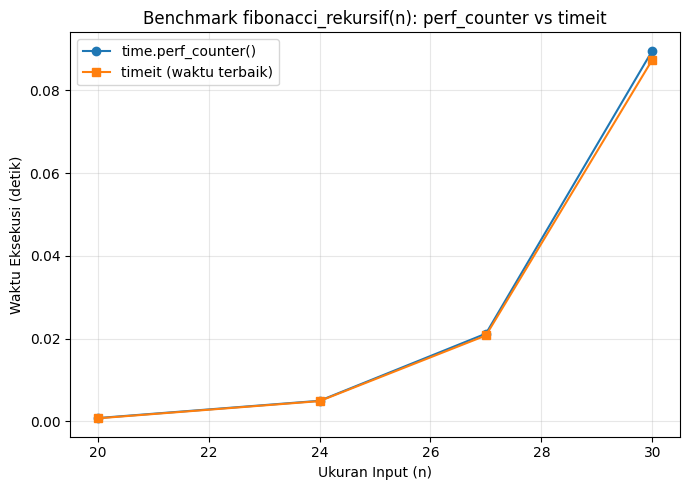

In [3]:
import time
import timeit

def fibonacci_rekursif(n):
    if n <= 1:
        return n
    return fibonacci_rekursif(n - 1) + fibonacci_rekursif(n - 2)

ukuran_input = [20, 24, 27, 30]

# --- Pengukuran manual dengan time.perf_counter() ---
waktu_perf_counter = []
for n in ukuran_input:
    start = time.perf_counter()
    hasil = fibonacci_rekursif(n)
    waktu = time.perf_counter() - start
    waktu_perf_counter.append(waktu)
    print(f"[perf_counter] n={n:>3} -> fib={hasil:<10} waktu={waktu:.4f} detik")

# --- Pengukuran berulang dengan timeit ---
waktu_timeit = []
for n in ukuran_input:
    hasil_timeit = timeit.repeat(
        stmt=f"fibonacci_rekursif({n})",
        globals=globals(),
        number=1,
        repeat=3,
    )
    waktu_terbaik = min(hasil_timeit)
    waktu_timeit.append(waktu_terbaik)
    print(f"[timeit]       n={n:>3} -> waktu terbaik dari 3 run = {waktu_terbaik:.4f} detik")

print("\nTabel perbandingan perf_counter vs timeit:")
print(f"{'N':>6} | {'perf_counter (s)':>18} | {'timeit terbaik (s)':>20}")
print("-" * 50)
for n, wp, wt in zip(ukuran_input, waktu_perf_counter, waktu_timeit):
    print(f"{n:>6} | {wp:>18.4f} | {wt:>20.4f}")

plt.figure(figsize=(7, 5))
plt.plot(ukuran_input, waktu_perf_counter, marker='o', label="time.perf_counter()")
plt.plot(ukuran_input, waktu_timeit, marker='s', label="timeit (waktu terbaik)")
plt.title("Benchmark fibonacci_rekursif(n): perf_counter vs timeit")
plt.xlabel("Ukuran Input (n)")
plt.ylabel("Waktu Eksekusi (detik)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Perbandingan hasil:  
`time.perf_counter()` dan `timeit` menunjukkan pola yang
sama, yaitu waktu eksekusi naik secara eksponensial seiring bertambahnya n
(sesuai kompleksitas O(2^n) dari fibonacci rekursif naif). Nilai dari `timeit`
sedikit lebih stabil/konsisten karena mengambil waktu terbaik dari beberapa
kali pengulangan (`repeat=3`), sehingga mengurangi pengaruh noise sistem
(proses lain di background, cache CPU, dsb), sedangkan `perf_counter` hanya
satu kali ukur sehingga lebih rentan terhadap variasi.

## Soal 4
 Refleksi Singkat (maks. 150 kata)

Hukum Amdahl lebih relevan ketika ukuran masalah bersifat tetap (fixed-size)
dan yang ingin dioptimalkan adalah waktu penyelesaian tugas yang sama dengan
menambah lebih banyak prosesor — disebut strong scaling. Contoh nyata:
merender satu video dengan durasi dan resolusi tertentu; menambah lebih banyak
core hanya mempercepat sampai batas tertentu karena ada bagian sekuensial
(misal encoding header) yang tidak bisa dipercepat.

Hukum Gustafson lebih relevan ketika ukuran masalah ikut membesar seiring
bertambahnya sumber daya — disebut weak scaling. Contoh nyata: simulasi
cuaca atau model iklim; jika tersedia lebih banyak prosesor, ilmuwan
cenderung memperbesar resolusi/wilayah simulasi (bukan mempercepat simulasi
yang sama), sehingga skala pekerjaan bertambah proporsional dengan jumlah
prosesor dan speedup terus tumbuh mendekati linear.

